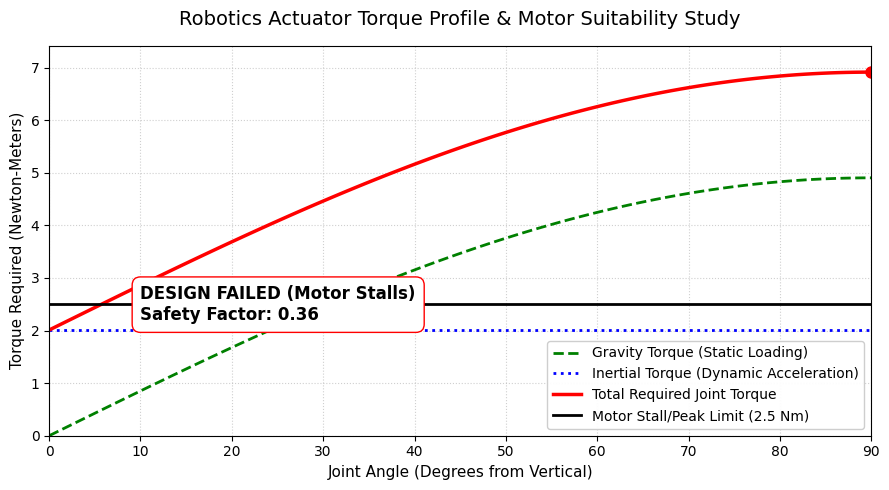

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. DESIGN SPECIFICATIONS (INPUT PARAMETERS)
LINK_MASS = 1.5       # Mass of the robot link in kg
LINK_LENGTH = 0.4     # Length of the link in meters
PAYLOAD_MASS = 0.5    # Weight the robot is holding at its tip (kg)
ACCEL_TIME = 0.5      # Time taken to accelerate to full speed (seconds)
TARGET_ANGLE = 90.0   # Total rotation in degrees
g = 9.81              # Acceleration due to gravity (m/s^2)

# Motor Specs to validate against (Example: NEMA 23 or small servo)
MOTOR_PEAK_TORQUE = 2.5 # Maximum torque output of your chosen motor in Nm

# 2. DYNAMIC CALCULATIONS
# Moment of Inertia (I) for a uniform slender rod spinning about its end + point payload
I_link = (1/3) * LINK_MASS * (LINK_LENGTH ** 2)
I_payload = PAYLOAD_MASS * (LINK_LENGTH ** 2)
I_total = I_link + I_payload

# Kinematics: Calculate required angular acceleration (alpha) assuming constant acceleration
rad_angle = np.radians(TARGET_ANGLE)
alpha = (2 * rad_angle) / (ACCEL_TIME ** 2) # alpha = 2*theta / t^2

# Generate angle array from 0 to 90 degrees to track across the motion path
angles_deg = np.linspace(0, TARGET_ANGLE, 100)
angles_rad = np.radians(angles_deg)

# 3. TORQUE PROFILES CALCULATIONS
# Static Gravity Torque changes with the sine of the angle (max torque at horizontal 90 deg)
# Center of mass of the link is at LINK_LENGTH / 2
torque_gravity = (LINK_MASS * g * (LINK_LENGTH / 2) + PAYLOAD_MASS * g * LINK_LENGTH) * np.sin(angles_rad)

# Dynamic Inertial Torque (Inertia * Angular Acceleration)
torque_inertia = np.full_like(angles_deg, I_total * alpha)

# Total Torque required at the joint
torque_total = torque_gravity + torque_inertia

# 4. PLOT ENGINEERING DESIGN CURVES
plt.figure(figsize=(9, 5))
plt.plot(angles_deg, torque_gravity, 'g--', label='Gravity Torque (Static Loading)', linewidth=2)
plt.plot(angles_deg, torque_inertia, 'b:', label='Inertial Torque (Dynamic Acceleration)', linewidth=2)
plt.plot(angles_deg, torque_total, 'r-', label='Total Required Joint Torque', linewidth=2.5)

# Add Motor Limit Line
plt.axhline(y=MOTOR_PEAK_TORQUE, color='black', linestyle='-', label=f'Motor Stall/Peak Limit ({MOTOR_PEAK_TORQUE} Nm)', linewidth=2)

# Identify peak stress point
max_torque = np.max(torque_total)
max_angle = angles_deg[np.argmax(torque_total)]

# Design check logic
safety_factor = MOTOR_PEAK_TORQUE / max_torque
if safety_factor > 1.0:
    status_text = f"DESIGN PASSED\nSafety Factor: {safety_factor:.2f}"
    status_color = 'green'
else:
    status_text = f"DESIGN FAILED (Motor Stalls)\nSafety Factor: {safety_factor:.2f}"
    status_color = 'red'

# Visual Annotations
plt.text(10, MOTOR_PEAK_TORQUE - 0.3, status_text, fontsize=12, fontweight='bold',
         bbox=dict(facecolor='white', edgecolor=status_color, boxstyle='round,pad=0.5'))
plt.plot(max_angle, max_torque, 'ro', markersize=8)

# Graph formatting
plt.title("Robotics Actuator Torque Profile & Motor Suitability Study", fontsize=14, pad=15)
plt.xlabel("Joint Angle (Degrees from Vertical)", fontsize=11)
plt.ylabel("Torque Required (Newton-Meters)", fontsize=11)
plt.xlim(0, TARGET_ANGLE)
plt.ylim(0, max(max_torque, MOTOR_PEAK_TORQUE) + 0.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()

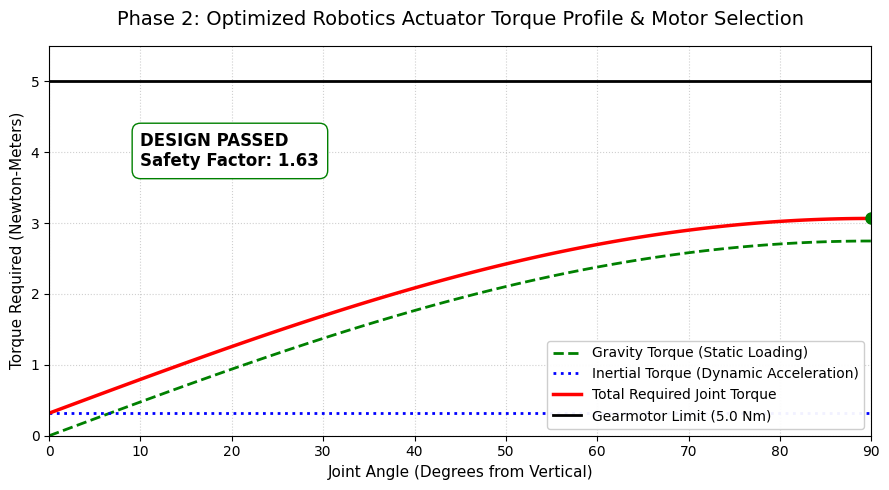

In [ ]:
LINK_MASS = 0.4       # FIX 1: Reduced mass by swapping to a carbon fiber/3D printed structure
LINK_LENGTH = 0.4     # Kept identical to maintain reach requirements
PAYLOAD_MASS = 0.5    # Kept identical to maintain payload requirements
ACCEL_TIME = 1.0      # FIX 2: Relaxed acceleration curve to lower transient inertial spikes
TARGET_ANGLE = 90.0
g = 9.81

# FIX 3: Upgraded to a motor configuration utilizing a 3:1 integrated gearbox reduction
MOTOR_PEAK_TORQUE = 5.0

# 2. DYNAMIC CALCULATIONS
I_link = (1/3) * LINK_MASS * (LINK_LENGTH ** 2)
I_payload = PAYLOAD_MASS * (LINK_LENGTH ** 2)
I_total = I_link + I_payload

rad_angle = np.radians(TARGET_ANGLE)
alpha = (2 * rad_angle) / (ACCEL_TIME ** 2)

angles_deg = np.linspace(0, TARGET_ANGLE, 100)
angles_rad = np.radians(angles_deg)

# 3. TORQUE PROFILES CALCULATIONS
torque_gravity = (LINK_MASS * g * (LINK_LENGTH / 2) + PAYLOAD_MASS * g * LINK_LENGTH) * np.sin(angles_rad)
torque_inertia = np.full_like(angles_deg, I_total * alpha)
torque_total = torque_gravity + torque_inertia

# 4. PLOT DESIGN CURVES FOR THE OPTIMIZED FIXED SYSTEM
plt.figure(figsize=(9, 5))
plt.plot(angles_deg, torque_gravity, 'g--', label='Gravity Torque (Static Loading)', linewidth=2)
plt.plot(angles_deg, torque_inertia, 'b:', label='Inertial Torque (Dynamic Acceleration)', linewidth=2)
plt.plot(angles_deg, torque_total, 'r-', label='Total Required Joint Torque', linewidth=2.5)

# Add Updated Motor Limit Line
plt.axhline(y=MOTOR_PEAK_TORQUE, color='black', linestyle='-', label=f'Gearmotor Limit ({MOTOR_PEAK_TORQUE} Nm)', linewidth=2)

# Identify peak stress point
max_torque = np.max(torque_total)
max_angle = angles_deg[np.argmax(torque_total)]

# Adjusted Design check logic for a passing system
safety_factor = MOTOR_PEAK_TORQUE / max_torque
if safety_factor > 1.0:
    status_text = f"DESIGN PASSED\nSafety Factor: {safety_factor:.2f}"
    status_color = 'green'
else:
    status_text = f"DESIGN FAILED (Motor Stalls)\nSafety Factor: {safety_factor:.2f}"
    status_color = 'red'

# Visual Annotations
plt.text(10, MOTOR_PEAK_TORQUE - 1.2, status_text, fontsize=12, fontweight='bold',
         bbox=dict(facecolor='white', edgecolor=status_color, boxstyle='round,pad=0.5'))
plt.plot(max_angle, max_torque, 'go', markersize=8) # Changed marker to green for success

# Graph formatting
plt.title("Phase 2: Optimized Robotics Actuator Torque Profile & Motor Selection", fontsize=14, pad=15)
plt.xlabel("Joint Angle (Degrees from Vertical)", fontsize=11)
plt.ylabel("Torque Required (Newton-Meters)", fontsize=11)
plt.xlim(0, TARGET_ANGLE)
plt.ylim(0, max(max_torque, MOTOR_PEAK_TORQUE) + 0.5)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', framealpha=0.95)
plt.tight_layout()
plt.show()